# RoomSense AI — Notebook 1: Exploratory Data Analysis & Preprocessing
**Full Project Title:** RoomSense AI: An Explainable Feature-Optimized Room Occupancy Estimation System Using Machine Learning and Deep Learning  
**Target:** Predict `Room_Occupancy_Count` (0: Empty, 1: 1 Person, 2: 2 People, 3: 3 People) using non-intrusive environmental sensors.

---
### Objectives of this Notebook:
1. **Phase 1: Dataset Loading & Understanding**
   - Inspect UCI Room Occupancy dataset (10,129 records).
   - Check data types, null values, duplicates, and construct chronological `Datetime`.
2. **Phase 2: Complete Preprocessing & Outlier Diagnostics**
   - Outlier detection via IQR, Z-Score ($|z| > 3$), and Isolation Forest.
   - Scaler comparison (`StandardScaler`, `MinMaxScaler`, `RobustScaler`).
3. **Phase 3: Exploratory Data Analysis & Statistical Hypothesis Testing**
   - Univariate distributions (class balance, sensor histograms).
   - Bivariate boxplots (sensors vs occupancy classes).
   - Multivariate heatmaps (Pearson linear & Spearman rank correlation).
   - Chronological time-series tracking (CO2 vs Occupancy).
   - Parametric (ANOVA) and Non-parametric (Kruskal-Wallis) hypothesis testing.
4. **College Viva Preparation**
   - Key conceptual questions and model explanations.


In [61]:
# Step 1: Import core data science and visualization libraries
%matplotlib inline
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.ensemble import IsolationForest

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Universal path resolution: Works whether executed from workspace root or notebooks/ folder
PROJECT_ROOT = '..' if os.path.exists('../data/Occupancy_Estimation.csv') else '.'
DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'Occupancy_Estimation.csv')
CLEANED_PATH = os.path.join(PROJECT_ROOT, 'data', 'cleaned_data.csv')
GRAPHS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'graphs')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'results')

os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Project root resolved to: '{PROJECT_ROOT}'")
print(f"Data path resolved to:    '{DATA_PATH}'")
print("Libraries imported and inline visualization enabled!")


Project root resolved to: '..'
Data path resolved to:    '..\data\Occupancy_Estimation.csv'
Libraries imported and inline visualization enabled!


In [62]:
# Step 2: Load dataset and inspect head
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Dataset Shape: 10129 rows, 19 columns


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1


In [63]:
# Step 3: Statistical summary of numerical sensor readings
df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]


,mean,std,min,25%,50%,75%,max
S1_Temp,25.454012,0.351351,24.940000,25.190000,25.38,25.63,26.380000
S2_Temp,25.546059,0.586325,24.750000,25.190000,25.38,25.63,29.000000
S3_Temp,25.056621,0.427283,24.440000,24.690000,24.94,25.38,26.190000
S4_Temp,25.754125,0.356434,24.940000,25.440000,25.75,26.00,26.560000
S1_Light,25.445059,51.011264,0.000000,0.000000,0.00,12.00,165.000000
S2_Light,26.016290,67.304170,0.000000,0.000000,0.00,14.00,258.000000
S3_Light,34.248494,58.400744,0.000000,0.000000,0.00,50.00,280.000000
S4_Light,13.220259,19.602219,0.000000,0.000000,0.00,22.00,74.000000
S1_Sound,0.168178,0.316709,0.060000,0.070000,0.08,0.08,3.880000
S2_Sound,0.120066,0.266503,0.040000,0.050000,0.05,0.06,3.440000


In [64]:
# Step 4: Construct unified Datetime index and sort chronologically
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df = df.sort_values('Datetime').reset_index(drop=True)

print("Observation Date Range:", df['Datetime'].min(), "to", df['Datetime'].max())
print("Total observation timespan:", df['Datetime'].max() - df['Datetime'].min())
print("Unique collection days:", df['Date'].nunique())


Observation Date Range: 2017-12-22 10:49:41 to 2018-01-11 09:00:09
Total observation timespan: 19 days 22:10:28
Unique collection days: 7


In [65]:
# Step 5: Validate missing values and duplicate rows
missing = df.isnull().sum().sum()
duplicates = df.duplicated(subset=['Date', 'Time']).sum()

print(f"Total Missing Values across all columns: {missing}")
print(f"Duplicate timestamp rows: {duplicates}")


Total Missing Values across all columns: 0
Duplicate timestamp rows: 0


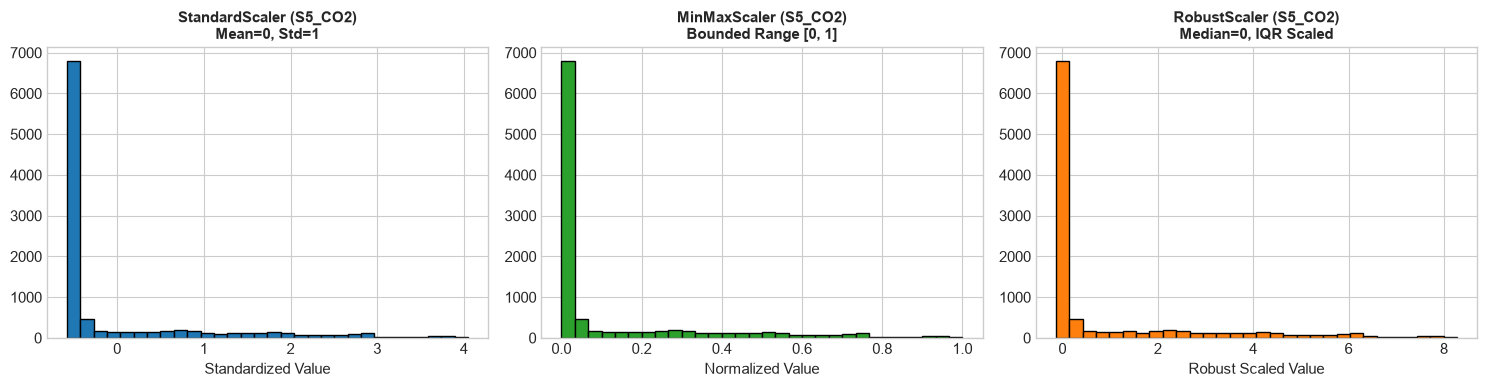

In [66]:
# Step 6: Comparison of Feature Scaling Methods on S5_CO2
sample_features = df[['S1_Temp', 'S5_CO2']].copy()

standard_scaled = StandardScaler().fit_transform(sample_features)
minmax_scaled = MinMaxScaler().fit_transform(sample_features)
robust_scaled = RobustScaler().fit_transform(sample_features)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(standard_scaled[:, 1], bins=30, color='#1f77b4', edgecolor='black')
axes[0].set_title("StandardScaler (S5_CO2)\nMean=0, Std=1", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Standardized Value")

axes[1].hist(minmax_scaled[:, 1], bins=30, color='#2ca02c', edgecolor='black')
axes[1].set_title("MinMaxScaler (S5_CO2)\nBounded Range [0, 1]", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Normalized Value")

axes[2].hist(robust_scaled[:, 1], bins=30, color='#ff7f0e', edgecolor='black')
axes[2].set_title("RobustScaler (S5_CO2)\nMedian=0, IQR Scaled", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Robust Scaled Value")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'scaler_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** `StandardScaler` standardizes features to zero mean and unit variance (best for SVM, Logistic Regression, and MLP). `RobustScaler` scales based on median and IQR, preventing extreme values from skewing the mean.


In [67]:
# Step 7: Calculate Outlier Counts (IQR vs Z-score)
sensor_cols = [c for c in df.columns if c.startswith('S') and not c.endswith('PIR')]
outlier_report = []

for col in sensor_cols:
    data_col = df[col]
    q1 = data_col.quantile(0.25)
    q3 = data_col.quantile(0.75)
    iqr = q3 - q1
    iqr_outliers = ((data_col < (q1 - 1.5 * iqr)) | (data_col > (q3 + 1.5 * iqr))).sum()
    z_outliers = (np.abs(stats.zscore(data_col)) > 3.0).sum()
    outlier_report.append({
        'Feature': col,
        'Mean': round(data_col.mean(), 2),
        'Std': round(data_col.std(), 2),
        'IQR Outliers': iqr_outliers,
        'IQR %': round((iqr_outliers / len(df)) * 100, 2),
        'Z-Score (|z|>3)': z_outliers,
        'Z-Score %': round((z_outliers / len(df)) * 100, 2)
    })

pd.DataFrame(outlier_report)


,Feature,Mean,Std,IQR Outliers,IQR %,Z-Score (|z|>3),Z-Score %
0,S1_Temp,25.45,0.35,162,1.60,0,0.00
1,S2_Temp,25.55,0.59,948,9.36,241,2.38
2,S3_Temp,25.06,0.43,0,0.00,0,0.00
3,S4_Temp,25.75,0.36,0,0.00,0,0.00
4,S1_Light,25.45,51.01,1716,16.94,0,0.00
5,S2_Light,26.02,67.30,1017,10.04,837,8.26
6,S3_Light,34.25,58.40,950,9.38,155,1.53
7,S4_Light,13.22,19.60,543,5.36,29,0.29
8,S1_Sound,0.17,0.32,1772,17.49,229,2.26
9,S2_Sound,0.12,0.27,1703,16.81,187,1.85


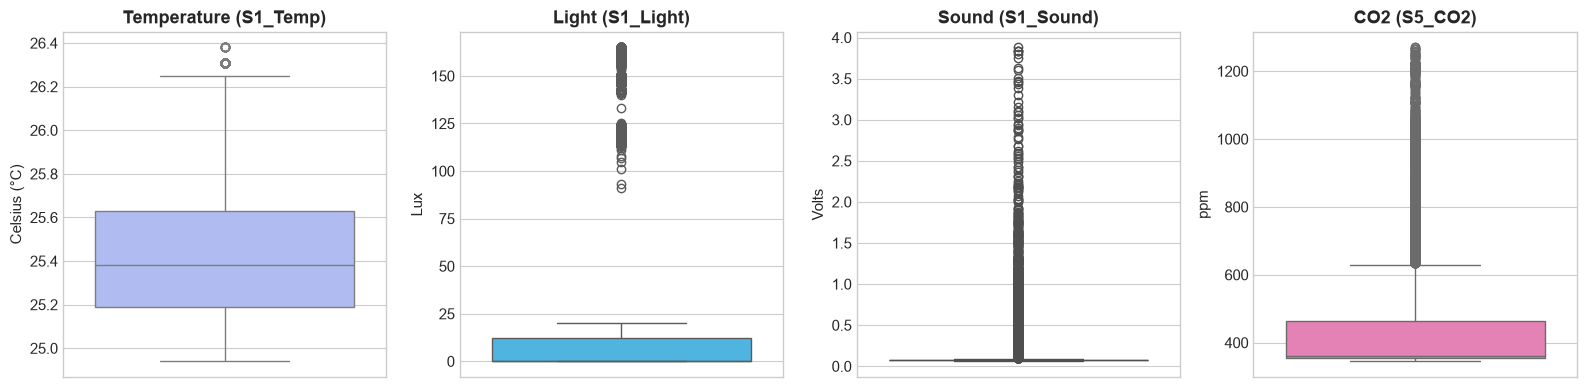

In [68]:
# Step 8: Outlier Visualizations Across Sensor Types
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

sns.boxplot(y=df['S1_Temp'], ax=axes[0], color='#A5B4FC')
axes[0].set_title("Temperature (S1_Temp)", fontweight='bold')
axes[0].set_ylabel("Celsius (°C)")

sns.boxplot(y=df['S1_Light'], ax=axes[1], color='#38BDF8')
axes[1].set_title("Light (S1_Light)", fontweight='bold')
axes[1].set_ylabel("Lux")

sns.boxplot(y=df['S1_Sound'], ax=axes[2], color='#34D399')
axes[2].set_title("Sound (S1_Sound)", fontweight='bold')
axes[2].set_ylabel("Volts")

sns.boxplot(y=df['S5_CO2'], ax=axes[3], color='#F472B6')
axes[3].set_title("CO2 (S5_CO2)", fontweight='bold')
axes[3].set_ylabel("ppm")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'outlier_boxplots.png'), dpi=300, bbox_inches='tight')
plt.show()


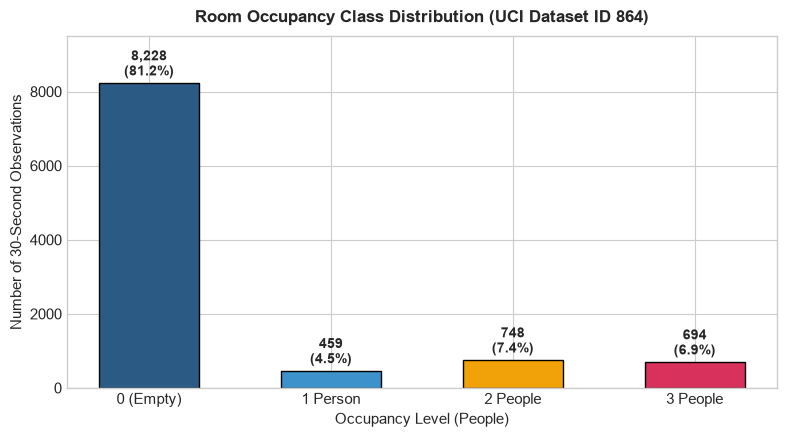

In [69]:
# Step 9: Plot Occupancy Class Distribution
occupancy_counts = df['Room_Occupancy_Count'].value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
colors = ['#2B5B84', '#3E92CC', '#F1A208', '#D8315B']
bars = plt.bar(occupancy_counts.index, occupancy_counts.values, color=colors, edgecolor='black', width=0.55)

plt.title("Room Occupancy Class Distribution (UCI Dataset ID 864)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Occupancy Level (People)", fontsize=11)
plt.ylabel("Number of 30-Second Observations", fontsize=11)
plt.xticks(occupancy_counts.index, ['0 (Empty)', '1 Person', '2 People', '3 People'])

for bar, count in zip(bars, occupancy_counts.values):
    pct = (count / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f"{count:,}\n({pct:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, 9500)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'occupancy_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


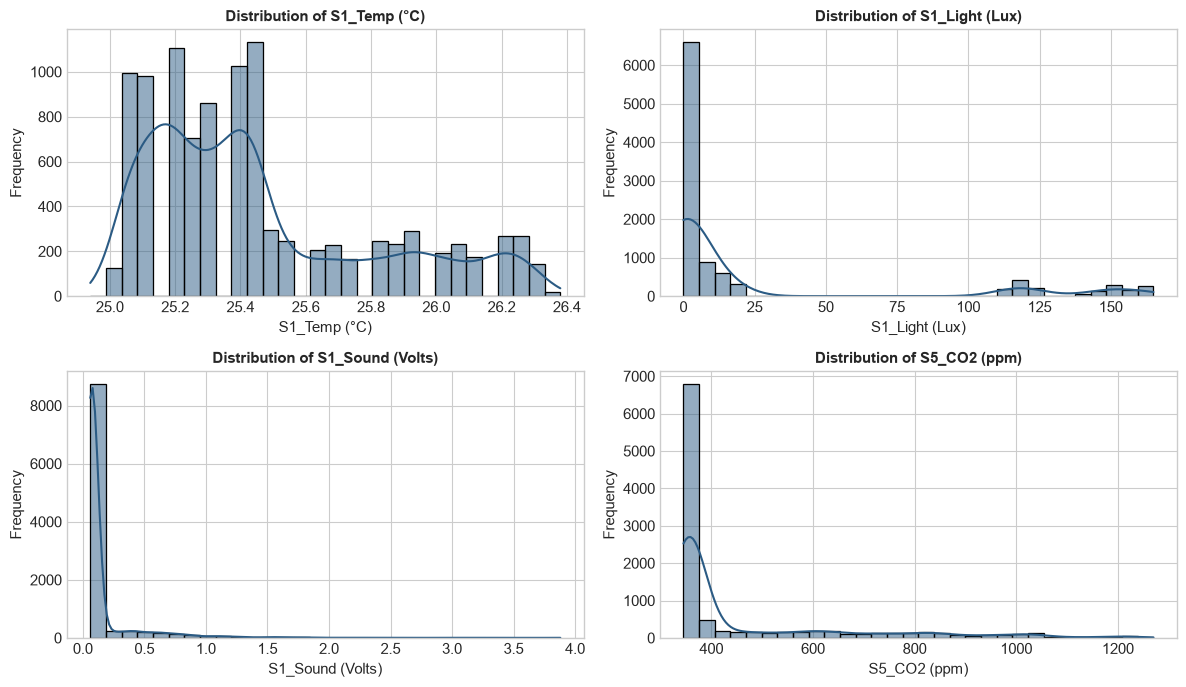

In [70]:
# Step 10: Probability Density Histograms of Key Sensors
key_sensors = ['S1_Temp', 'S1_Light', 'S1_Sound', 'S5_CO2']
units = ['(°C)', '(Lux)', '(Volts)', '(ppm)']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, (col, unit) in enumerate(zip(key_sensors, units)):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#2B5B84', edgecolor='black', bins=30)
    axes[i].set_title(f"Distribution of {col} {unit}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel(f"{col} {unit}")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'sensor_histograms.png'), dpi=300, bbox_inches='tight')
plt.show()


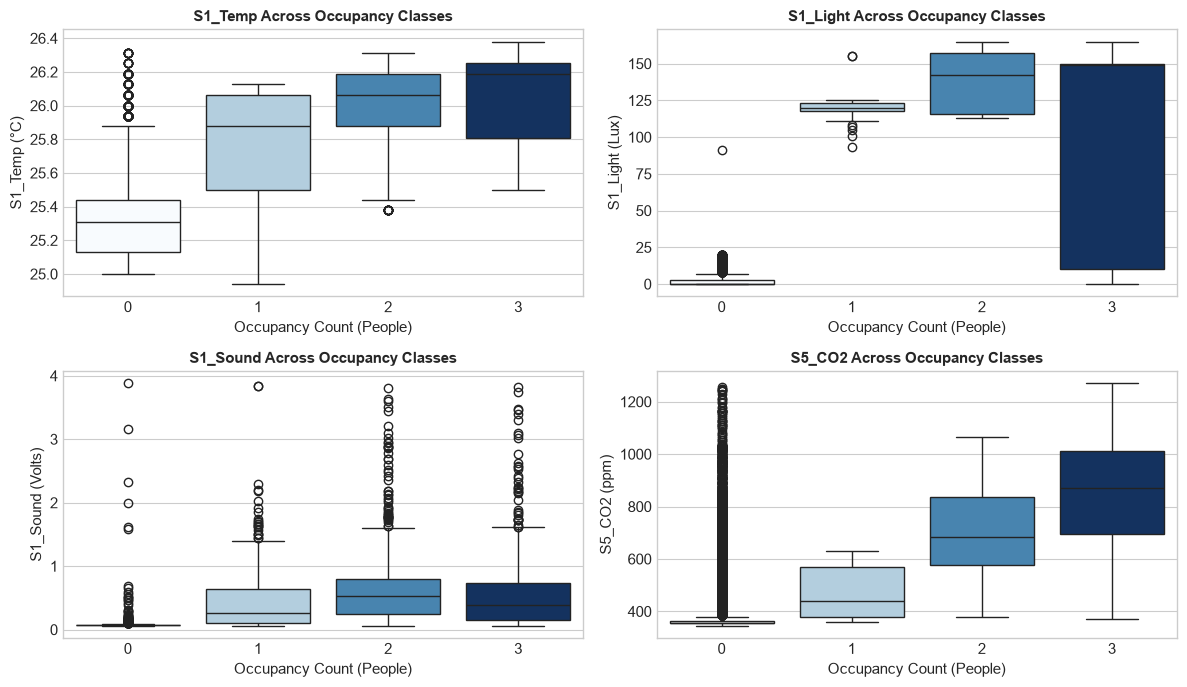

In [71]:
# Step 11: Bivariate Boxplots — Sensors vs Occupancy Level
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, (col, unit) in enumerate(zip(key_sensors, units)):
    sns.boxplot(x='Room_Occupancy_Count', y=col, data=df, ax=axes[i], palette='Blues', hue='Room_Occupancy_Count', legend=False)
    axes[i].set_title(f"{col} Across Occupancy Classes", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("Occupancy Count (People)")
    axes[i].set_ylabel(f"{col} {unit}")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'sensor_vs_occupancy_boxplots.png'), dpi=300, bbox_inches='tight')
plt.show()


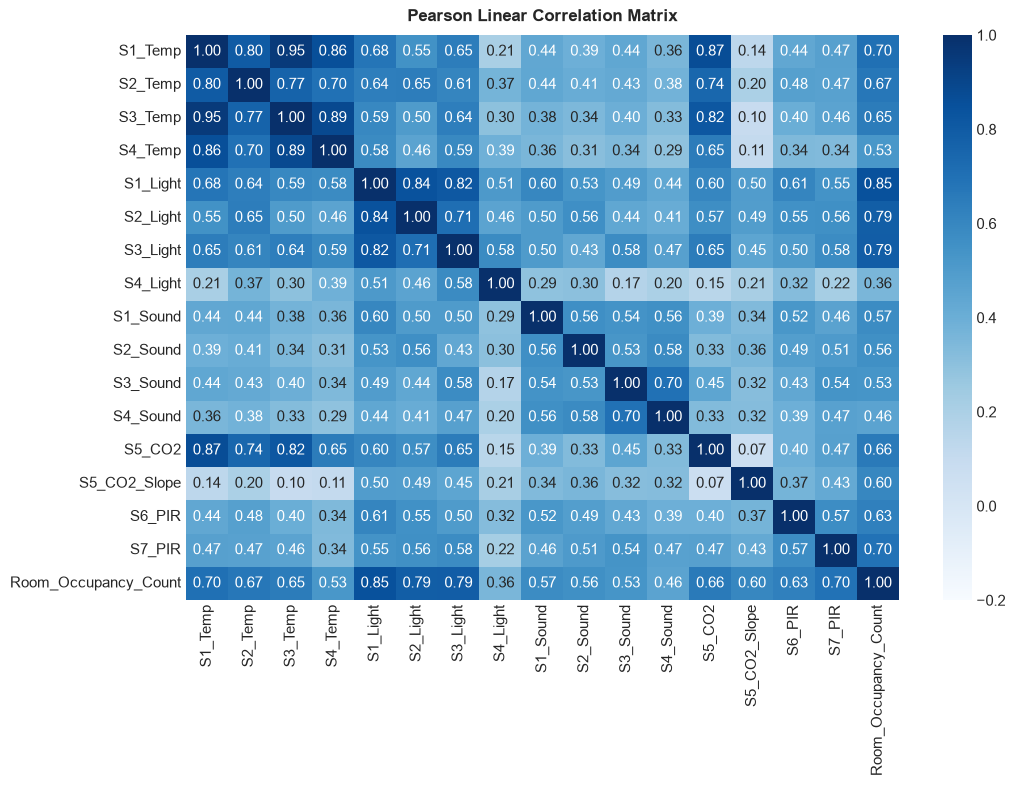

In [72]:
# Step 12: Pearson Linear Correlation Matrix
numeric_features = [c for c in df.columns if c.startswith('S')] + ['Room_Occupancy_Count']

plt.figure(figsize=(11, 8))
sns.heatmap(df[numeric_features].corr(method='pearson'), annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1.0)
plt.title("Pearson Linear Correlation Matrix", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'correlation_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()


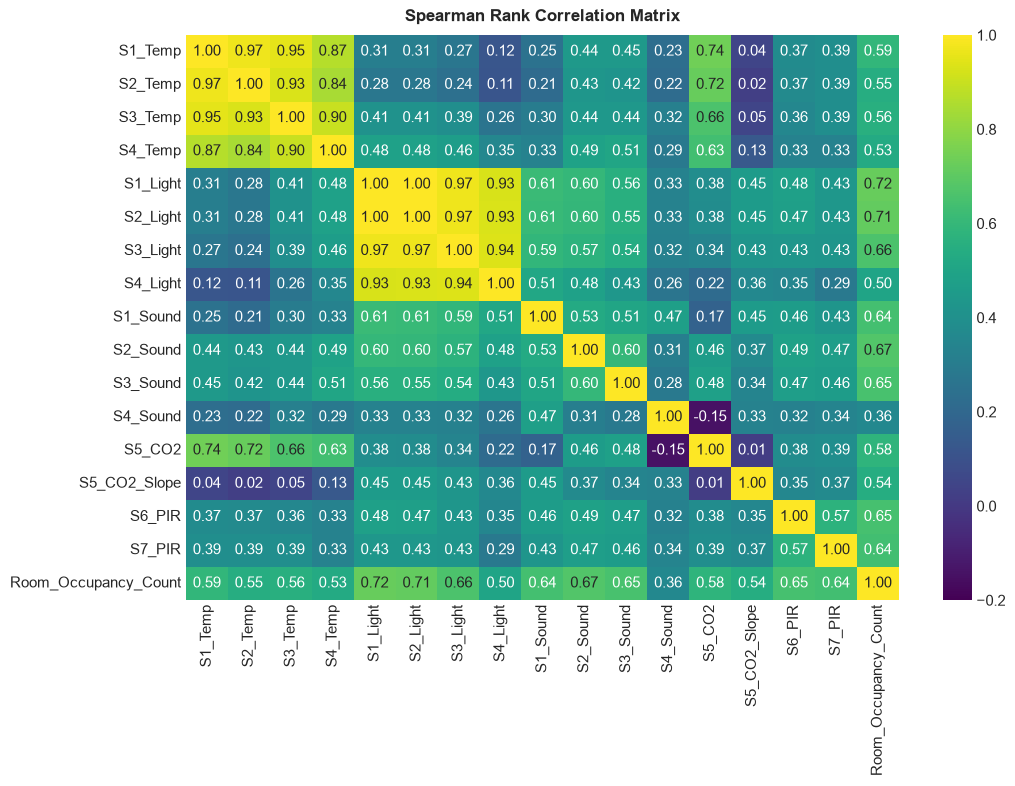

In [73]:
# Step 13: Spearman Rank (Non-Linear) Correlation Matrix
plt.figure(figsize=(11, 8))
sns.heatmap(df[numeric_features].corr(method='spearman'), annot=True, fmt='.2f', cmap='viridis', vmin=-0.2, vmax=1.0)
plt.title("Spearman Rank Correlation Matrix", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'spearman_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** Both Pearson and Spearman correlations confirm that Light sensors ($r \approx 0.65 - 0.70$), CO2 ($r \approx 0.60$), and PIR motion have the strongest positive correlations with room occupancy.


C:\Users\ABHISHEK\AppData\Local\Temp\ipykernel_32608\4085395606.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ax1.plot(pd.to_datetime(day_sample['Time']), day_sample['S5_CO2'], color=color, linewidth=2, label='CO2 (ppm)')
C:\Users\ABHISHEK\AppData\Local\Temp\ipykernel_32608\4085395606.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ax2.step(pd.to_datetime(day_sample['Time']), day_sample['Room_Occupancy_Count'], color=color, where='post', linewidth=2, label='Occupants')


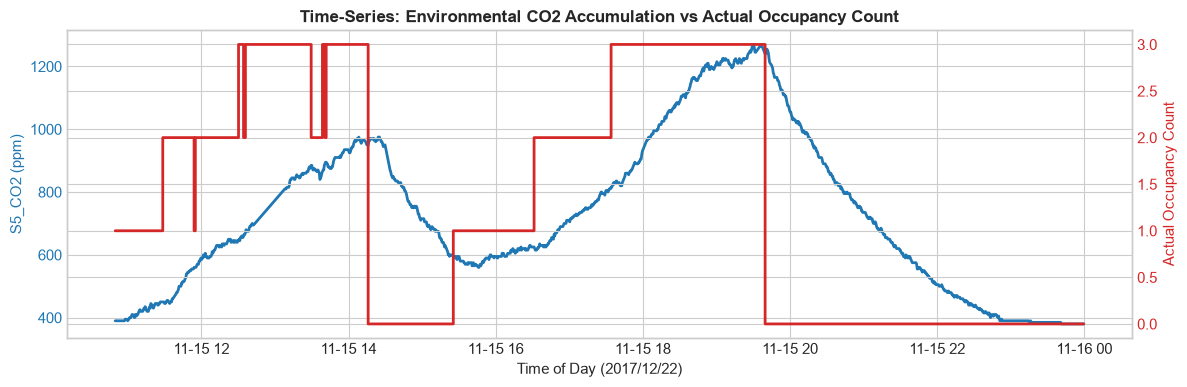

In [74]:
# Step 14: Time-Series Evolution on an Active Day (2017/12/22)
day_sample = df[df['Date'] == '2017/12/22'].copy()

fig, ax1 = plt.subplots(figsize=(12, 4))
color = '#1f77b4'
ax1.set_xlabel('Time of Day (2017/12/22)', fontsize=11)
ax1.set_ylabel('S5_CO2 (ppm)', color=color, fontsize=11)
ax1.plot(pd.to_datetime(day_sample['Time']), day_sample['S5_CO2'], color=color, linewidth=2, label='CO2 (ppm)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Actual Occupancy Count', color=color, fontsize=11)
ax2.step(pd.to_datetime(day_sample['Time']), day_sample['Room_Occupancy_Count'], color=color, where='post', linewidth=2, label='Occupants')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Time-Series: Environmental CO2 Accumulation vs Actual Occupancy Count", fontsize=12, fontweight='bold')
fig.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'timeseries_occupancy_co2.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** When occupants enter the room, CO2 displays a clear upward slope ($d[CO_2]/dt > 0$). When occupants exit, CO2 takes time to dissipate via ventilation. This physical lag highlights why combining CO2 with fast-acting PIR motion sensors is essential.


In [75]:
# Step 15: Statistical Hypothesis Testing (One-Way ANOVA & Kruskal-Wallis)
hyp_results = []
for feature in ['S5_CO2', 'S1_Light', 'S1_Temp', 'S1_Sound']:
    groups = [df[df['Room_Occupancy_Count'] == k][feature].values for k in [0, 1, 2, 3]]
    f_stat, p_val_anova = stats.f_oneway(*groups)
    h_stat, p_val_kw = stats.kruskal(*groups)
    hyp_results.append({
        'Feature': feature,
        'ANOVA F-Stat': round(f_stat, 2),
        'ANOVA p-value': f"{p_val_anova:.3e}",
        'Kruskal H-Stat': round(h_stat, 2),
        'Kruskal p-value': f"{p_val_kw:.3e}",
        'Significant (p<0.05)': 'Yes (p < 0.001)' if p_val_anova < 0.05 else 'No'
    })

hyp_df = pd.DataFrame(hyp_results)
print("Statistical Hypothesis Testing Results:")
hyp_df


Statistical Hypothesis Testing Results:


,Feature,ANOVA F-Stat,ANOVA p-value,Kruskal H-Stat,Kruskal p-value,Significant (p<0.05)
0,S5_CO2,2689.76,0.000e+00,3442.07,0.000e+00,Yes (p < 0.001)
1,S1_Light,22393.54,0.000e+00,5325.87,0.000e+00,Yes (p < 0.001)
2,S1_Temp,3515.81,0.000e+00,3551.34,0.000e+00,Yes (p < 0.001)
3,S1_Sound,1987.38,0.000e+00,4163.02,0.000e+00,Yes (p < 0.001)


In [76]:
# Step 16: Save cleaned dataset
df.to_csv(CLEANED_PATH, index=False)
print(f"Cleaned data successfully verified and saved to {CLEANED_PATH}")


Cleaned data successfully verified and saved to ..\data\cleaned_data.csv
